In [43]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

In [44]:
df = sns.load_dataset("taxis")

In [45]:
df

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn


In [46]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [47]:
df.dtypes

pickup             datetime64[us]
dropoff            datetime64[us]
passengers                  int64
distance                  float64
fare                      float64
tip                       float64
tolls                     float64
total                     float64
color                         str
payment                       str
pickup_zone                   str
dropoff_zone                  str
pickup_borough                str
dropoff_borough               str
dtype: object

In [48]:
df.isnull().sum()[df.isnull().sum()>0]

payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [49]:
no_col = df.select_dtypes(include=["int64","float64"]).columns
no_col

Index(['passengers', 'distance', 'fare', 'tip', 'tolls', 'total'], dtype='str')

In [50]:
cat_col = df.select_dtypes(include=["str"]).columns
cat_col

Index(['color', 'payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough',
       'dropoff_borough'],
      dtype='str')

In [51]:
for col in no_col:
    df[col] = df[col].fillna(df[col].median())

In [52]:
for col in cat_col:
    df[col] = df[col].fillna(df[col].mode()[0])
        

In [53]:
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

In [54]:
df = df.dropna(subset=["pickup","dropoff"])

In [55]:
df["pickup"] = pd.to_datetime(df["pickup"])

In [56]:
df = df.sort_values(by="pickup")

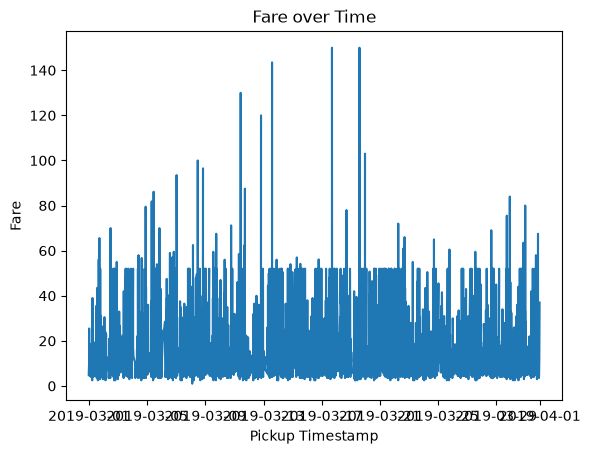

In [57]:
plt.plot(df["pickup"], df["fare"])
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare")
plt.title("Fare over Time")
plt.show()

In [59]:
b_fare = df.groupby("pickup_borough")["fare"].sum()
b_fare

pickup_borough
Bronx         2078.91
Brooklyn      6327.48
Manhattan    59426.42
Queens       16382.06
Name: fare, dtype: float64

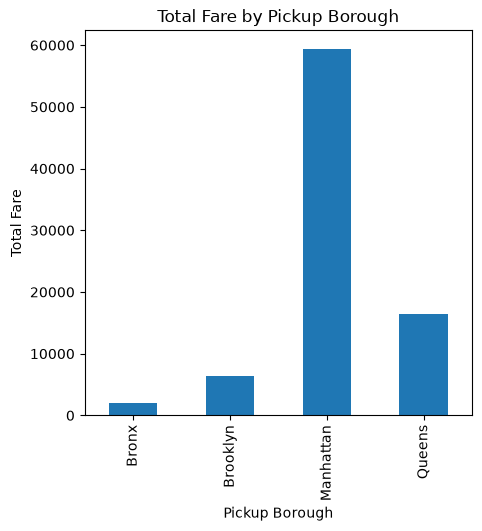

In [71]:
plt.figure(figsize=(5,5))
b_fare.plot(kind="bar")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.title("Total Fare by Pickup Borough")
plt.show()

In [64]:
count_of_payment = df["payment"].value_counts()
count_of_payment 

payment
credit card    4621
cash           1812
Name: count, dtype: int64

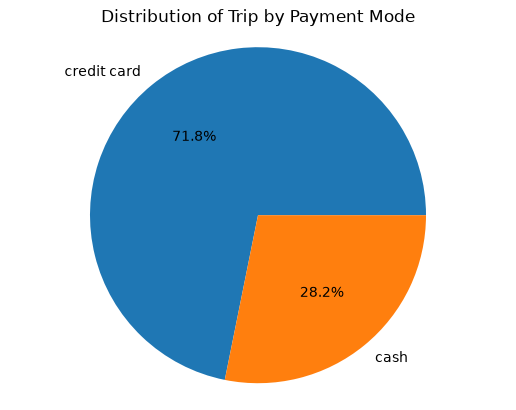

In [73]:
count_of_payment.plot(kind = "pie", autopct="%1.1f%%")
plt.title("Distribution of Trip by Payment Mode")
plt.axis('equal')
plt.show()

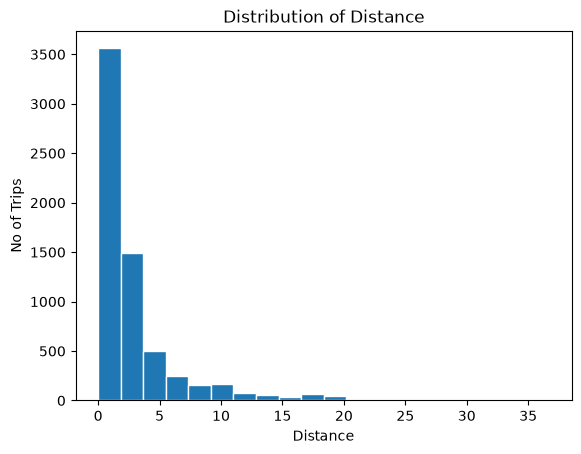

In [67]:
plt.figure()
plt.hist(df["distance"], bins = 20, edgecolor = "white")
plt.xlabel("Distance")
plt.ylabel("No of Trips")
plt.title("Distribution of Distance")
plt.show()

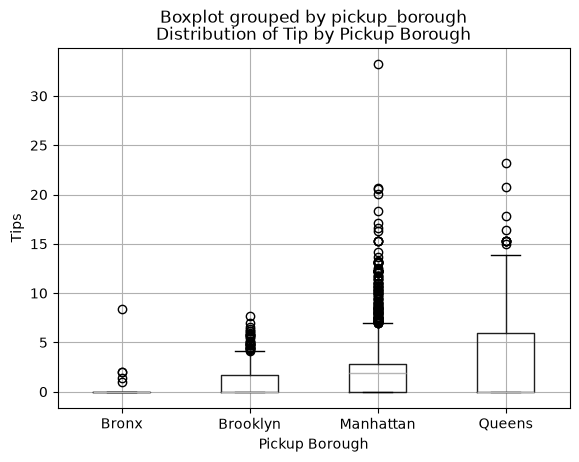

In [75]:
df.boxplot(column = "tip", by = "pickup_borough")
plt.title("Distribution of Tip by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Tips")
plt.show()

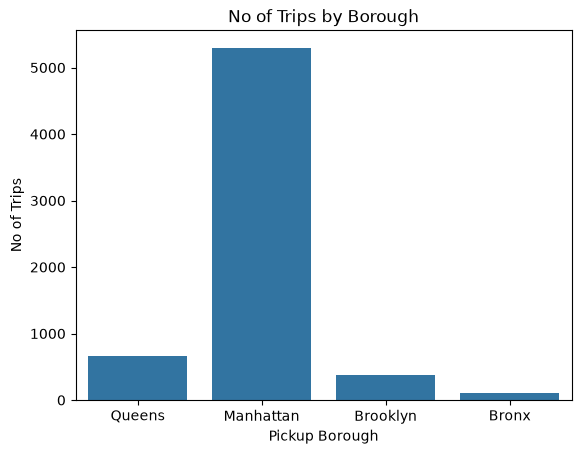

In [77]:
sns.countplot(x="pickup_borough", data=df)
plt.title("No of Trips by Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("No of Trips")
plt.show()

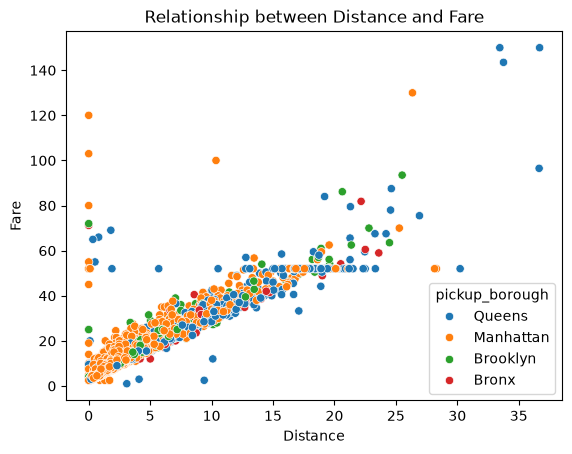

In [83]:
sns.scatterplot(x="distance", y="fare", hue="pickup_borough", data=df)
plt.title("Relationship between Distance and Fare")
plt.xlabel("Distance")
plt.ylabel("Fare")
plt.show()

In [86]:
numeric_df = df[["distance", "fare", "tip", "tolls", "total"]]
numeric_df.corr()

,distance,fare,tip,tolls,total
distance,1.000000,0.920108,0.452589,0.635267,0.904676
fare,0.920108,1.000000,0.488612,0.609307,0.974358
tip,0.452589,0.488612,1.000000,0.413619,0.646186
tolls,0.635267,0.609307,0.413619,1.000000,0.683142
total,0.904676,0.974358,0.646186,0.683142,1.000000


Text(0.5, 1.0, 'Correlation Heatmap')

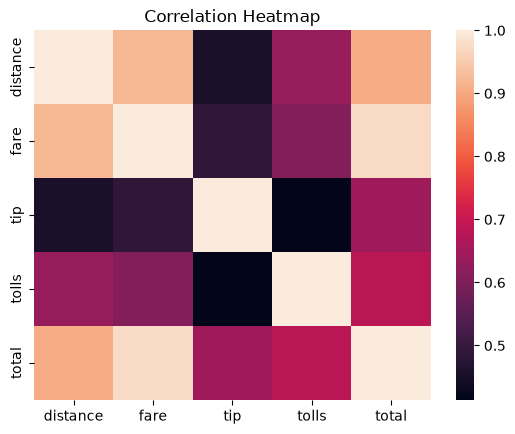

In [91]:
sns.heatmap(numeric_df.corr())
plt.title("Correlation Heatmap")

In [122]:
pair_data = df[["distance", "fare", "tip", "total","pickup_zone"]]

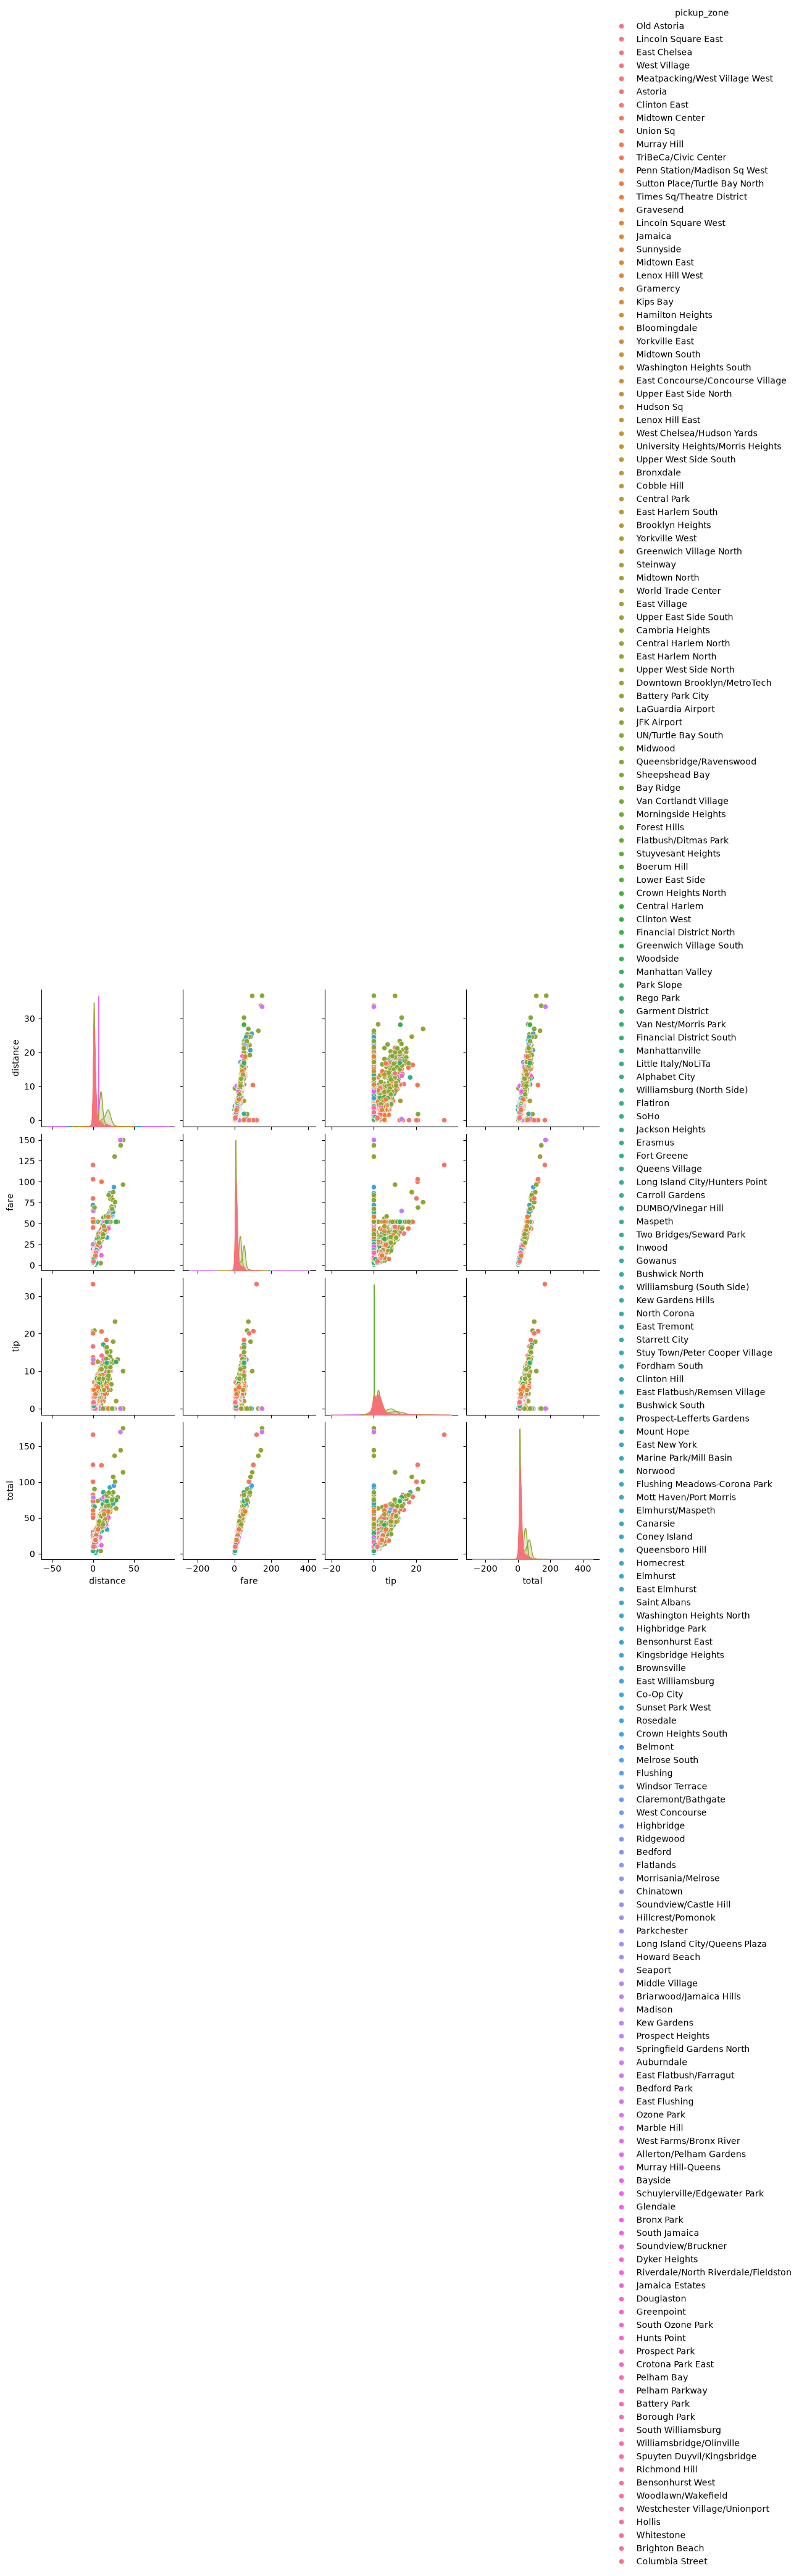

In [126]:
sns.pairplot(data=pair_data, hue = "pickup_zone")
plt.show()

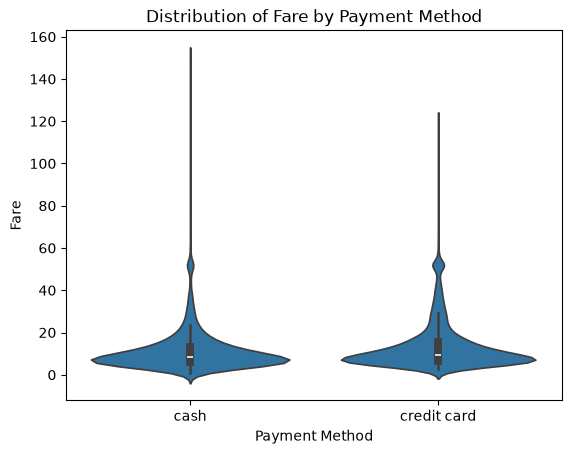

In [132]:
sns.violinplot(x="payment", y="fare", data=df)
plt.title("Distribution of Fare by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare")
plt.show()